# Задание 2.10

Напишите программу с использованием инструментария *Jupyter Notebook*, которая изображает на сфере Римана следующие кривые:

**а)** прямую; **б)** окружность; **в)** параболу; **г)** гиперболу.

## Теория

**Сфера Римана.** Поставим на комплексную плоскость сферу диаметра $1$, касающуюся плоскости в начале координат:

$$
\xi^2+\eta^2+\left(\zeta-\tfrac12\right)^2=\tfrac14 ,
$$

$S=(0,0,0)$ — южный полюс (точка касания), $N=(0,0,1)$ — северный полюс.

**Стереографическая проекция** сопоставляет точке $z=x+iy$ плоскости точку пересечения сферы с отрезком $Nz$. Точки этого отрезка имеют вид $(tx,\ ty,\ 1-t)$; подставляя в уравнение сферы, получаем $t=\dfrac{1}{1+|z|^2}$, откуда

$$
\xi=\frac{x}{1+|z|^2},\qquad \eta=\frac{y}{1+|z|^2},\qquad \zeta=\frac{|z|^2}{1+|z|^2}.
$$

При $|z|\to\infty$ образ точки стремится к полюсу $N$, поэтому $N$ изображает бесконечно удалённую точку: $\overline{\mathbb C}=\mathbb C\cup\{\infty\}$.

**Круговое свойство.** Любая прямая или окружность плоскости задаётся уравнением $A(x^2+y^2)+Bx+Cy+D=0$. Подставив $x=\dfrac{\xi}{1-\zeta}$, $y=\dfrac{\eta}{1-\zeta}$, $x^2+y^2=\dfrac{\zeta}{1-\zeta}$, получим уравнение **плоскости** $A\zeta+B\xi+C\eta+D(1-\zeta)=0$, а сечение сферы плоскостью — окружность. Поэтому:

- **а) прямая** ($A=0$) переходит в окружность на сфере, **проходящую через $N$** (прямая «проходит через $\infty$»);
- **б) окружность** ($A\ne0$) переходит в окружность на сфере, не проходящую через $N$.

**Кривые второго порядка**, не являющиеся окружностями, в плоские сечения сферы не переходят:

- **в) парабола** уходит в бесконечность обеими ветвями в одном направлении (вдоль своей оси), поэтому её образ — замкнутая «капля» с **остриём в полюсе $N$**;
- **г) гипербола** состоит из двух ветвей, каждая из которых уходит в бесконечность вдоль двух асимптот. Образ каждой ветви — петля, начинающаяся и заканчивающаяся в $N$, а вся гипербола переходит в **«восьмёрку» с самопересечением в $N$** (касательные в $N$ направлены вдоль асимптот).

**Как строим.** Кривую задаём параметрически. Чтобы образ на сфере дошёл до полюса, параметр неограниченных кривых берём в виде $t=\operatorname{tg}s$, $s\in\left(-\frac\pi2,\frac\pi2\right)$. На плоскости рисуем часть кривой, попавшую в квадрат $[-L,L]^2$, на сфере — образ всей кривой; часть образа на обратной стороне сферы рисуем бледной линией. Штриховая линия — проектирующий луч из полюса $N$.

а) прямая: образ на сфере — плоская кривая (окружность)? да
б) окружность: образ на сфере — плоская кривая (окружность)? да
в) парабола: образ на сфере — плоская кривая (окружность)? нет
г) гипербола: образ на сфере — плоская кривая (окружность)? нет


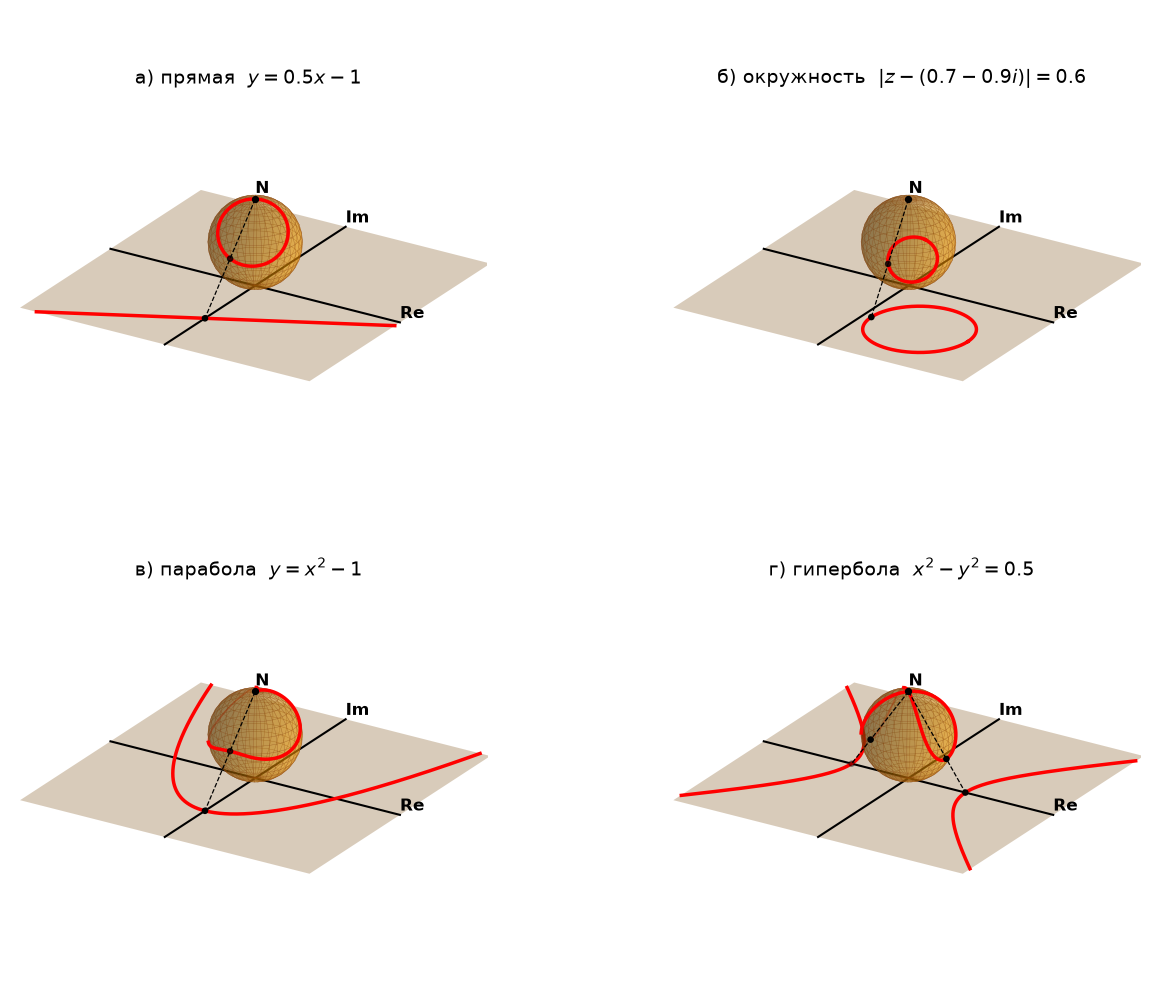

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def stereo(x, y):
    """Стереографическая проекция точки z = x + iy на сферу Римана
    ξ² + η² + (ζ - 1/2)² = 1/4 (проектируем из северного полюса N = (0, 0, 1))."""
    d = 1 + x**2 + y**2
    return x/d, y/d, (x**2 + y**2)/d


def draw_scene(ax, L, elev=24, azim=-58):
    """Плоскость z = 0 с осями Re, Im и сфера Римана, касающаяся плоскости в нуле."""
    ax.computed_zorder = False              # порядок рисования задаём сами через zorder
    ax.view_init(elev=elev, azim=azim)
    ax.set_proj_type('ortho')

    # Плоскость и оси
    PX, PY = np.meshgrid([-L, L], [-L, L])
    ax.plot_surface(PX, PY, 0*PX, color='burlywood', alpha=0.45, zorder=0)
    ax.plot([-L, L], [0, 0], [0, 0], color='k', lw=1.5, zorder=1)
    ax.plot([0, 0], [-L, L], [0, 0], color='k', lw=1.5, zorder=1)
    ax.text(L, 0, 0.05, "Re", fontsize=12, weight='bold')
    ax.text(0, L, 0.05, "Im", fontsize=12, weight='bold')

    # Сфера: центр (0, 0, 1/2), радиус 1/2 (сетка меридианов и параллелей)
    u, v = np.meshgrid(np.linspace(0, 2*np.pi, 37), np.linspace(0, np.pi, 19))
    ax.plot_surface(0.5*np.cos(u)*np.sin(v), 0.5*np.sin(u)*np.sin(v), 0.5 + 0.5*np.cos(v),
                    color='orange', alpha=0.35, edgecolor='saddlebrown', linewidth=0.3, zorder=3)
    ax.scatter([0], [0], [1], color='k', s=18, zorder=7)
    ax.text(0, 0, 1.07, "N", fontsize=12, weight='bold')

    ax.set_xlim(-L, L)
    ax.set_ylim(-L, L)
    ax.set_zlim(0, 1)
    ax.set_box_aspect((2*L, 2*L, 1), zoom=1.0)     # одинаковый масштаб по всем осям
    ax.set_axis_off()


def draw_curve(ax, x, y, L):
    """Кривая (x, y) на плоскости и её образ на сфере Римана."""
    # На плоскости — часть кривой, попадающая в изображаемый квадрат
    inside = (np.abs(x) <= L) & (np.abs(y) <= L)
    ax.plot(np.where(inside, x, np.nan), np.where(inside, y, np.nan), 0*x, color='red', lw=2.5, zorder=2)

    # Образ на сфере: ближнюю к наблюдателю часть рисуем жирно, дальнюю — бледно
    xi, eta, zeta = stereo(x, y)
    el, az = np.radians(ax.elev), np.radians(ax.azim)
    cam = np.array([np.cos(el)*np.cos(az), np.cos(el)*np.sin(az), np.sin(el)])   # направление на наблюдателя
    front = xi*cam[0] + eta*cam[1] + (zeta - 0.5)*cam[2] >= 0
    for mask, style in ((~front, dict(lw=1.2, alpha=0.45, zorder=2)), (front, dict(lw=2.5, zorder=5))):
        ax.plot(np.where(mask, xi, np.nan), np.where(mask, eta, np.nan), np.where(mask, zeta, np.nan),
                color='red', **style)

    # Проектирующий луч: полюс N -> точка сферы -> точка плоскости (для середины кривой)
    i = len(x)//2
    ax.plot([0, x[i]], [0, y[i]], [1, 0], color='k', lw=0.9, ls='--', zorder=6)
    ax.scatter([x[i], xi[i]], [y[i], eta[i]], [0, zeta[i]], color='k', s=14, zorder=7)


def is_planar(parts):
    """Лежит ли образ кривой на сфере в одной плоскости (т.е. является ли он окружностью)?"""
    P = np.column_stack([np.concatenate(c) for c in zip(*[stereo(x, y) for x, y in parts])])
    return np.linalg.svd(P - P.mean(axis=0), compute_uv=False)[-1] < 1e-8


L = 1.8                                       # на плоскости рисуем квадрат [-L, L] × [-L, L]
s = np.linspace(-np.pi/2, np.pi/2, 4001)[1:-1]
t = np.tan(s)                                 # параметр, пробегающий всю прямую (-inf, +inf)
phi = np.linspace(0, 2*np.pi, 1001)
a = np.sqrt(0.5)                              # полуось гиперболы

# Параметрические уравнения кривых (гипербола состоит из двух ветвей)
curves = {
    "а) прямая  $y = 0.5x - 1$": [(t, 0.5*t - 1)],
    "б) окружность  $|z - (0.7 - 0.9i)| = 0.6$": [(0.7 + 0.6*np.cos(phi), -0.9 + 0.6*np.sin(phi))],
    "в) парабола  $y = x^2 - 1$": [(t, t**2 - 1)],
    "г) гипербола  $x^2 - y^2 = 0.5$": [(a*np.cosh(4*s), a*np.sinh(4*s)), (-a*np.cosh(4*s), a*np.sinh(4*s))],
}

fig = plt.figure(figsize=(15, 10))
for k, (title, parts) in enumerate(curves.items(), start=1):
    ax = fig.add_subplot(2, 2, k, projection='3d')
    draw_scene(ax, L)
    for x, y in parts:
        draw_curve(ax, x, y, L)
    ax.set_title(title, fontsize=14, y=0.9)
    name = title.split("  ")[0]
    print(f"{name}: образ на сфере — плоская кривая (окружность)? {'да' if is_planar(parts) else 'нет'}")

plt.tight_layout()
plt.show()